# UCS420 Lab Assignment 9 — NLP Text Preprocessing (Completed Starter)

**Student:** Jaskirat Singh Chatha  
**Roll number:** 1024170312 Run all cells from top to bottom in Google Colab. The original `generate_dataset()` and `process_ticket()` definitions are preserved unchanged. The assignment results depend on your roll-number-generated tickets, so run the notebook to produce your exact tables, examples, and plot.

In [1]:
# Enter your own details when prompted. Do not use another student's roll number.
ROLL_NO = 1024170312
NAME = "Jaskirat Singh Chatha"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "A valid roll number and name are required."

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170312   Name: Jaskirat Singh Chatha   Fingerprint: 8B6EC17F   Tickets: 14

Ticket_ID                                                                         Ticket_Text
      T01                     The password is showing an error. It works on another computer.
      T02           I am unable to use the lms while uploading the file. It worked yesterday.
      T03                            The laptop is running slowly. Is there another solution?
      T04      VPN stopped responding after restarting the system. I don't know what changed.
      T05                   MATLAB is not working since yesterday. I don't know what changed.
      T06 I was locked out of the server while uploading the file. Is there another solution?
      T07                 I am unable to use the VPN on my laptop. Is there another solution?
      T08                                                Python 3.12 was installed yesterday.
      T09                               Laptop has stopped sy

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Q1. Run the official preprocessing pipeline on every ticket.
from IPython.display import display

processed = [process_ticket(text) for text in df["Ticket_Text"]]
q1_rows = []
for (_, row), result in zip(df.iterrows(), processed):
    q1_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

q1_table = pd.DataFrame(q1_rows)
total_row = {"Ticket_ID": "TOTAL"}
for col in q1_table.columns[1:]:
    total_row[col] = int(q1_table[col].sum())
# Unique tokens are not additive across tickets; report the corpus-wide unique count.
all_q1_tokens = [token for result in processed for token in result["tokens"]]
total_row["Unique tokens"] = len(set(all_q1_tokens))
q1_table = pd.concat([q1_table, pd.DataFrame([total_row])], ignore_index=True)
display(q1_table)

# Show full pipeline output for the two focus tickets generated by the starter.
print("Focus tickets:", FOCUS)
for ticket_id in FOCUS:
    idx = df.index[df["Ticket_ID"] == ticket_id]
    if len(idx):
        result = processed[int(idx[0])]
        print(f"\\n{ticket_id}: {df.loc[idx[0], 'Ticket_Text']}")
        print("Sentences:", result["sentences"])
        print("Tokens:", result["tokens"])
        print("Punctuation tokens:", result["punct"])
        print("Stopwords:", result["stops"])
        print("Final tokens:", result["final"])

# Save the table for submission/use outside Colab.
q1_table.to_csv(f"{ROLL_NO}_Q1_preprocessing.csv", index=False)

,Ticket_ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,13,2,5,12,6
1,T02,2,16,2,7,14,7
2,T03,2,11,2,4,10,5
3,T04,2,15,2,5,14,8
4,T05,2,14,2,5,13,7
5,T06,2,17,2,9,16,6
6,T07,2,16,2,8,16,6
7,T08,1,6,1,1,6,4
8,T09,2,11,2,3,9,6
9,T10,2,11,2,3,10,6


Focus tickets: ['T08', 'T14']
\nT08: Python 3.12 was installed yesterday.
Sentences: ['Python 3.12 was installed yesterday.']
Tokens: ['python', '3.12', 'was', 'installed', 'yesterday', '.']
Punctuation tokens: ['.']
Stopwords: ['was']
Final tokens: ['python', '3.12', 'installed', 'yesterday']
\nT14: I can't login and I didn't change anything.
Sentences: ["I can't login and I didn't change anything."]
Tokens: ['i', 'ca', "n't", 'login', 'and', 'i', 'did', "n't", 'change', 'anything', '.']
Punctuation tokens: ['.']
Stopwords: ['i', 'and', 'i', 'did']
Final tokens: ['ca', "n't", 'login', "n't", 'change', 'anything']


**Observation — run this cell to obtain an answer based on your generated data.**

Some final tokens may not be complete dictionary words. They usually come from `word_tokenize()` splitting contractions into fragments such as `n't`, `'s`, or `ca`. These fragments are retained by the official pipeline if they are neither punctuation-only tokens nor English stopwords.

```python
final_vocab = sorted(set(token for result in processed for token in result["final"]))
contraction_fragments = [t for t in final_vocab if t in {"n't", "'s", "'re", "'ve", "'ll", "'d", "'m", "ca", "wo"}]
print("Contraction-related fragments found:", contraction_fragments)
```

The printed list identifies which such fragments actually occur in this roll-number-specific dataset.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

REGEX_PATTERNS = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    # Keep dotted version numbers and decimals together, plus integers/grouped amounts.
    "Numbers (decimals/versions included)": r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.])\d{1,3}(?:,\d{3})+(?!\w)|(?<![\w.])\d+(?![\w.])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words beginning with a vowel": r"\b[AEIOUaeiou][A-Za-z]*(?:['’][A-Za-z]+)?\b"
}

def redact_sensitive(text):
    # URL first, to prevent digits in URLs from being treated as phone numbers.
    text = re.sub(r"\b(?:https?://|www\.)[^\s<>]+", "<URL>", text, flags=re.IGNORECASE)
    text = re.sub(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b", "<EMAIL>", text)
    # Matches common international, 10-digit, and landline-style phone formats.
    text = re.sub(
        r"(?<!\w)(?:\+\d{1,3}[-.\s]?)?(?:\(?\d{2,5}\)?[-.\s]?)\d{3,5}[-.\s]?\d{3,5}(?!\w)",
        "<PHONE>", text
    )
    return text

# Run both the regex extraction and replacement on the generated tickets.
for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print(f"\\n{row['Ticket_ID']}: {text}")
    for label, pattern in REGEX_PATTERNS.items():
        print(f"{label}: {re.findall(pattern, text)}")
    print("Redacted:", redact_sensitive(text))

# The provided TEST_LINES are explicit required test cases.
print("\\n===== TEST_LINES validation =====")
for line in TEST_LINES:
    print("\\nOriginal:", line)
    for label, pattern in REGEX_PATTERNS.items():
        print(f"{label}: {re.findall(pattern, line)}")
    print("Redacted:", redact_sensitive(line))

\nT01: The password is showing an error. It works on another computer.
Words longer than 5 letters: ['password', 'showing', 'another', 'computer']
Numbers (decimals/versions included): []
Capitalized words: ['The', 'It']
Words beginning with a vowel: ['is', 'an', 'error', 'It', 'on', 'another']
Redacted: The password is showing an error. It works on another computer.
\nT02: I am unable to use the lms while uploading the file. It worked yesterday.
Words longer than 5 letters: ['unable', 'uploading', 'worked', 'yesterday']
Numbers (decimals/versions included): []
Capitalized words: ['I', 'It']
Words beginning with a vowel: ['I', 'am', 'unable', 'use', 'uploading', 'It']
Redacted: I am unable to use the lms while uploading the file. It worked yesterday.
\nT03: The laptop is running slowly. Is there another solution?
Words longer than 5 letters: ['laptop', 'running', 'slowly', 'another', 'solution']
Numbers (decimals/versions included): []
Capitalized words: ['The', 'Is']
Words beginning w

**Observation — capitalized words that occur only because they start a sentence**

The capitalized-word regex also captures ordinary words at sentence beginnings, such as `The`, `I`, or `Please`. The following cell compares capitalized words with sentence-initial words in the generated tickets. It reports the count of sentence-initial capitalized occurrences and examples.

```python
sentence_initial_capitalized = []
for text in df["Ticket_Text"]:
    for sentence in sent_tokenize(text):
        match = re.match(r"\s*([A-Z][a-zA-Z]*)\b", sentence)
        if match:
            word = match.group(1)
            # Exclude likely acronyms/product names only heuristically; report examples for inspection.
            sentence_initial_capitalized.append(word)
print("Sentence-initial capitalized occurrences:", len(sentence_initial_capitalized))
print("Examples:", sentence_initial_capitalized)
print("These are often capitalized by sentence position rather than because they are proper nouns.")
```

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
# Q3. One RegexpTokenizer pattern that preserves the required multi-character forms.
from nltk.tokenize import RegexpTokenizer

CUSTOM_PATTERN = (
    r"(?i:https?://[^\s<>\"']+|www\.[^\s<>\"']+)"   # URLs
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"  # emails
    r"|(?:\+\d{1,3}[-.\s]?)?(?:\(?\d{2,5}\)?[-.\s]?)\d{3,5}[-.\s]?\d{3,5}"  # phone-like numbers
    r"|\d+(?:\.\d+)+"                                # decimals and versions
    r"|[A-Za-z0-9]+(?:[-'][A-Za-z0-9]+)*"            # words, contractions, hyphenated terms
    r"|[^\w\s]"                                      # remaining punctuation
)
custom_tokenizer = RegexpTokenizer(CUSTOM_PATTERN)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("===== TEST_LINES =====")
for line in TEST_LINES:
    print("\\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

print("\\n===== Generated tickets =====")
tokenization_comparisons = []
for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])
    differs = custom != standard
    tokenization_comparisons.append({
        "Ticket_ID": row["Ticket_ID"],
        "Different?": differs,
        "Custom token count": len(custom),
        "word_tokenize count": len(standard)
    })
    print(f"{row['Ticket_ID']} | different={differs}")
    print("  custom:", custom)
    print("  word_tokenize:", standard)

q3_comparison = pd.DataFrame(tokenization_comparisons)
display(q3_comparison)
different_count = int(q3_comparison["Different?"].sum())
print(f"Tickets tokenized differently: {different_count} out of {len(df)}")
q3_comparison.to_csv(f"{ROLL_NO}_Q3_tokenizer_comparison.csv", index=False)

===== TEST_LINES =====
\nText: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
\nText: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
\nText: The state-of-the-art lab isn't open; log-in at 5.3

,Ticket_ID,Different?,Custom token count,word_tokenize count
0,T01,False,13,13
1,T02,False,16,16
2,T03,False,11,11
3,T04,True,14,15
4,T05,True,13,14
5,T06,False,17,17
6,T07,False,16,16
7,T08,False,6,6
8,T09,False,11,11
9,T10,False,11,11


Tickets tokenized differently: 5 out of 14


**Observation:** The cell below gives the exact count from your generated tickets. Differences are expected because the custom tokenizer deliberately keeps contractions (`isn't`), hyphenated words (`state-of-the-art`), decimals/versions, emails, URLs, and phone numbers as single tokens, whereas `word_tokenize()` commonly splits some of these forms.

```python
print(f"{different_count} of {len(df)} tickets have different token lists.")
```

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
# Q4. Compare stemmers and POS-aware lemmatization on unique final tokens.
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

unique_final_tokens = sorted(set(
    token.lower()
    for result in processed
    for token in result["final"]
    if re.search(r"[A-Za-z]", token)
))

def penn_to_wordnet(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("N"): return wordnet.NOUN
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

tagged_tokens = nltk.pos_tag(unique_final_tokens)
pos_map = {word: penn_to_wordnet(tag) for word, tag in tagged_tokens}

# Select a suffix after inspecting actual vocabulary, preferring one occurring in >=2 words.
suffix_candidates = ["ing", "ed", "es", "s", "ly", "tion"]
chosen_suffix = None
suffix_examples = []
for suffix in suffix_candidates:
    examples = [w for w in unique_final_tokens if len(w) > len(suffix) + 1 and w.endswith(suffix)]
    if len(examples) >= 2:
        chosen_suffix, suffix_examples = suffix, examples[:8]
        break
if chosen_suffix is None:
    # Still define a transparent rule and report if there are not two supporting examples.
    chosen_suffix = "s"
    suffix_examples = [w for w in unique_final_tokens if w.endswith("s")][:8]

regexp_stemmer = RegexpStemmer(chosen_suffix + "$", min=3)
print("Chosen RegexpStemmer suffix:", repr(chosen_suffix))
print("Dataset words supporting this suffix:", suffix_examples)
if len(suffix_examples) < 2:
    print("Note: this generated dataset did not provide two words for the candidate suffix list.")

stem_rows = []
for word in unique_final_tokens:
    porter_out = porter.stem(word)
    lancaster_out = lancaster.stem(word)
    regex_out = regexp_stemmer.stem(word)
    lemma_out = lemmatizer.lemmatize(word, pos=pos_map.get(word, wordnet.NOUN))
    outputs = [porter_out, lancaster_out, regex_out, lemma_out]
    if len(set(outputs)) > 1:
        stem_rows.append({
            "Word": word,
            "Porter": porter_out,
            "Lancaster": lancaster_out,
            "Regexp": regex_out,
            "WordNet lemma (POS-aware)": lemma_out,
            "POS tag": pos_map.get(word, wordnet.NOUN)
        })

stem_comparison = pd.DataFrame(stem_rows, columns=[
    "Word", "Porter", "Lancaster", "Regexp", "WordNet lemma (POS-aware)", "POS tag"
])
display(stem_comparison)
stem_comparison.to_csv(f"{ROLL_NO}_Q4_stemming_lemmatization.csv", index=False)

Chosen RegexpStemmer suffix: 'ing'
Dataset words supporting this suffix: ['anything', 'asking', 'opening', 'responding', 'restarting', 'running', 'showing', 'syncing']


,Word,Porter,Lancaster,Regexp,WordNet lemma (POS-aware),POS tag
0,another,anoth,anoth,another,another,n
1,anything,anyth,anyth,anyth,anything,n
2,change,chang,chang,change,change,v
3,changed,chang,chang,changed,change,v
4,closed,close,clos,closed,closed,a
5,computer,comput,comput,computer,computer,n
6,crashes,crash,crash,crashes,crash,n
7,details,detail,detail,details,detail,n
8,error,error,er,error,error,v
9,file,file,fil,file,file,n


**Observation:** The comparison table above is dataset-specific. To identify over- and under-stemming, run the following helper and inspect the suggested examples.

```python
# Over-stemming: a stemmer maps a word to a form that looks too truncated or unlike its base.
print("Possible over-stemming examples (word -> Lancaster stem):")
shown = 0
for word in unique_final_tokens:
    stem = lancaster.stem(word)
    if stem != word and (len(stem) <= 3 or not stem.isalpha()):
        print(word, "->", stem)
        shown += 1
        if shown == 5: break

# Under-stemming: related forms that a method leaves distinct.
print("Possible under-stemming candidates (different forms retained):")
for word in unique_final_tokens:
    if word.endswith(("ing", "ed", "s")) and porter.stem(word) == word:
        print(word, "is unchanged by Porter")
```

Over-stemming occurs when too much of a word is removed or words with different meanings are conflated. Under-stemming occurs when related forms are not reduced to a common stem. Use the printed rows to quote actual examples from your dataset.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Set,Total tokens,Unique tokens,TTR
0,S1: all tokens,174,83,0.477011
1,S2: no punctuation,147,78,0.530612
2,S3: final tokens,84,55,0.654762
3,S4: S3 after Porter,83,51,0.614458


Top 10 words of S1


,Word,Frequency
0,.,21
1,the,10
2,i,9
3,is,7
4,laptop,5
5,n't,5
6,another,4
7,it,3
8,on,3
9,use,3


Top 10 words of S3


,Word,Frequency
0,laptop,5
1,n't,5
2,another,4
3,use,3
4,yesterday,3
5,solution,3
6,know,3
7,changed,3
8,unable,2
9,uploading,2


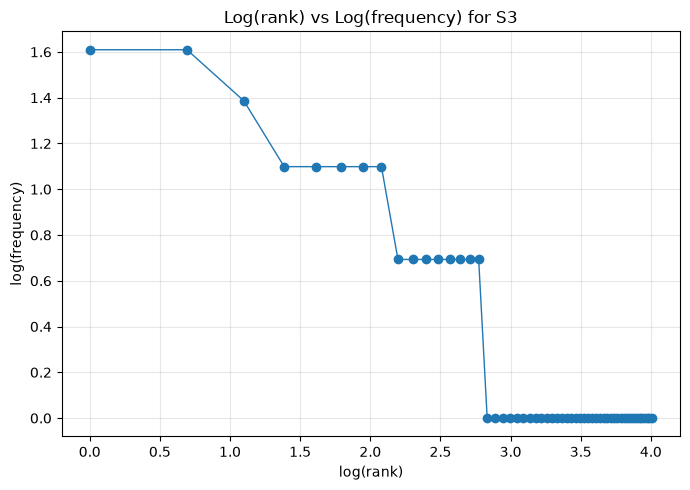

Top 5 bigrams of S1


,Bigram,Frequency
0,"(., i)",6
1,"(yesterday, .)",3
2,"(., the)",3
3,"(., is)",3
4,"(is, there)",3


Top 5 bigrams of S3


,Bigram,Frequency
0,"(another, solution)",3
1,"(n't, know)",3
2,"(know, changed)",3
3,"(unable, use)",2
4,"(uploading, file)",2


In [11]:
# Q5. Build S1–S4 from the official process_ticket() outputs.
import math
import matplotlib.pyplot as plt
from collections import Counter
S1 = [token for result in processed for token in result["tokens"]]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for result in processed for token in result["final"]]
S4 = [porter.stem(token) for token in S3 if re.search(r"[A-Za-z]", token)]

def corpus_row(name, sequence):
    total = len(sequence)
    unique = len(set(sequence))
    return {
        "Set": name,
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": unique / total if total else 0.0
    }

corpus_stats = pd.DataFrame([
    corpus_row("S1: all tokens", S1),
    corpus_row("S2: no punctuation", S2),
    corpus_row("S3: final tokens", S3),
    corpus_row("S4: S3 after Porter", S4)
])
display(corpus_stats)

def print_top_words(sequence, n=10):
    table = pd.DataFrame(Counter(sequence).most_common(n), columns=["Word", "Frequency"])
    display(table)
    return table

print("Top 10 words of S1")
top10_S1 = print_top_words(S1, 10)
print("Top 10 words of S3")
top10_S3 = print_top_words(S3, 10)

# Zipf-style log(rank) versus log(frequency) plot for S3.
frequency_values = sorted(Counter(S3).values(), reverse=True)
rank_values = list(range(1, len(frequency_values) + 1))
plt.figure(figsize=(7, 5))
plt.plot([math.log(rank) for rank in rank_values],
         [math.log(freq) for freq in frequency_values], marker="o", linewidth=1)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log(rank) vs Log(frequency) for S3")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

def bigram_table(sequence, n=5):
    bigrams = list(zip(sequence, sequence[1:]))
    return pd.DataFrame(Counter(bigrams).most_common(n), columns=["Bigram", "Frequency"])

print("Top 5 bigrams of S1")
display(bigram_table(S1, 5))
print("Top 5 bigrams of S3")
display(bigram_table(S3, 5))

corpus_stats.to_csv(f"{ROLL_NO}_Q5_corpus_statistics.csv", index=False)

**Observation:** TTR (type-token ratio) is the number of unique tokens divided by the total number of tokens. From S1 to S4, punctuation and stopwords are removed to form S3, and Porter stemming then maps some related word forms to the same stem in S4. Therefore, the number of unique types and the total token count both change, so TTR can increase or decrease depending on the vocabulary in the generated tickets. Use the printed `corpus_stats` table to state the exact direction and values for your dataset.